In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import tensorflow as tf
import numpy as np
import os, shutil, hashlib
from pathlib import Path
import matplotlib.pyplot as plt



In [2]:
import kagglehub

path = kagglehub.dataset_download("emmarex/plantdisease")
print("Dataset downloaded to:", path)


Dataset downloaded to: /kaggle/input/datasets/emmarex/plantdisease


In [3]:
 
SOURCE_DIR = os.path.join(path, "PlantVillage")
if not os.path.isdir(SOURCE_DIR):
    subdirs = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
    SOURCE_DIR = os.path.join(path, subdirs[0])

RAW_DIR = "/content/plantvillage_raw"
if not os.path.isdir(RAW_DIR):
    shutil.copytree(SOURCE_DIR, RAW_DIR)

print("RAW_DIR:", RAW_DIR)
print(os.listdir(RAW_DIR)[:20])


RAW_DIR: /content/plantvillage_raw
['Tomato__Target_Spot', 'Pepper__bell___healthy', 'Potato___healthy', 'Tomato__Tomato_mosaic_virus', 'Potato___Early_blight', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Late_blight', 'Potato___Late_blight', 'Tomato_Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_Leaf_Mold', 'Tomato_Early_blight', 'Tomato_healthy']


In [5]:
from PIL import Image

VALID_EXT = (".jpg", ".jpeg", ".png")

def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

def clean_corrupted_and_wrong_ext(data_dir):
    removed = 0
    for class_dir in Path(data_dir).iterdir():
        if not class_dir.is_dir():
            continue
        for f in class_dir.iterdir():
            if not f.is_file():
                continue
            try:
                if f.suffix.lower() not in VALID_EXT:
                    f.unlink()
                    removed += 1
                    continue
                if not is_valid_image(f):
                    f.unlink()
                    removed += 1
            except PermissionError:
                print(f"Skipped (no permission to delete): {f}")
    print(f"Removed {removed} corrupted/invalid images")

clean_corrupted_and_wrong_ext(RAW_DIR)


Removed 0 corrupted/invalid images


In [6]:
def remove_duplicates(data_dir):
    removed = 0
    for class_dir in Path(data_dir).iterdir():
        if not class_dir.is_dir():
            continue
        seen_hashes = {}
        for f in class_dir.iterdir():
            if not f.is_file():
                continue
            try:
                with open(f, "rb") as fh:
                    h = hashlib.md5(fh.read()).hexdigest()
            except Exception:
                continue
            if h in seen_hashes:
                f.unlink()
                removed += 1
            else:
                seen_hashes[h] = f
    print(f"Removed {removed} duplicate images")

remove_duplicates(RAW_DIR)


Removed 14 duplicate images


In [7]:
MIN_SIZE = 32  # pixels

def remove_tiny_images(data_dir, min_size=MIN_SIZE):
    removed = 0
    for class_dir in Path(data_dir).iterdir():
        if not class_dir.is_dir():
            continue
        for f in class_dir.iterdir():
            if not f.is_file():
                continue
            try:
                with Image.open(f) as img:
                    w, h = img.size
                if w < min_size or h < min_size:
                    f.unlink()
                    removed += 1
            except Exception:
                f.unlink()
                removed += 1
    print(f"Removed {removed} tiny images")

remove_tiny_images(RAW_DIR)


Removed 0 tiny images


Pepper__bell___Bacterial_spot: 997
Pepper__bell___healthy: 1478
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Tomato_Bacterial_spot: 2127
Tomato_Early_blight: 1000
Tomato_Late_blight: 1901
Tomato_Leaf_Mold: 952
Tomato_Septoria_leaf_spot: 1771
Tomato_Spider_mites_Two_spotted_spider_mite: 1676
Tomato__Target_Spot: 1404
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208
Tomato__Tomato_mosaic_virus: 373
Tomato_healthy: 1585


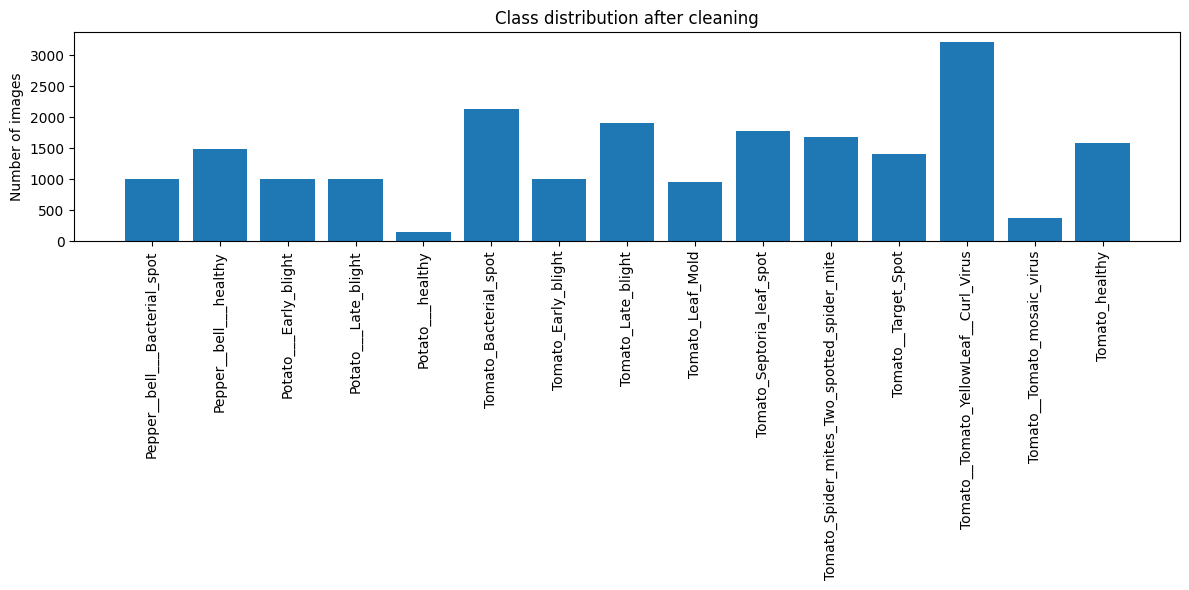

Number of classes: 15


In [8]:
class_counts = {}
for class_dir in sorted(Path(RAW_DIR).iterdir()):
    if class_dir.is_dir():
        n = len(list(class_dir.glob("*")))
        class_counts[class_dir.name] = n

for cls, n in class_counts.items():
    print(f"{cls}: {n}")

plt.figure(figsize=(12, 6))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=90)
plt.ylabel("Number of images")
plt.title("Class distribution after cleaning")
plt.tight_layout()
plt.show()

NUM_CLASSES = len(class_counts)
print("Number of classes:", NUM_CLASSES)


In [9]:
!pip -q install split-folders

import splitfolders

output_folder = "/content/PlantVillageSplit"

splitfolders.ratio(
    RAW_DIR,
    output=output_folder,
    seed=42,
    ratio=(0.7, 0.15, 0.15)
)


Copying files: 20624 files [00:03, 6265.93 files/s]


In [10]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{output_folder}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{output_folder}/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{output_folder}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print(class_names)


Found 14430 files belonging to 15 classes.


I0000 00:00:1786228689.244267      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786228689.247059      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 3087 files belonging to 15 classes.
Found 3107 files belonging to 15 classes.
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [12]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


In [14]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [15]:
from tensorflow.keras import layers, Model

inputs = tf.keras.Input(shape=(224, 224, 3))

x = tf.keras.applications.efficientnet.preprocess_input(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs)


In [16]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,068,786 (15.52 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [17]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)


Epoch 1/30


2026-08-08 22:40:20.056906: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:20.200080: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:20.545341: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:20.686351: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:21.467603: E external/local_xla/xla/stream_

289/451 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.5329 - loss: 1.6273

2026-08-08 22:40:44.132521: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:44.275589: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:44.620752: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:44.761436: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:40:45.544474: E external/local_xla/xla/stream_

450/451 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6002 - loss: 1.4129

2026-08-08 22:41:11.901169: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:41:12.040613: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:41:12.360671: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:41:12.501392: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 22:41:13.262592: E external/local_xla/xla/stream_

451/451 ━━━━━━━━━━━━━━━━━━━━ 88s 108ms/step - accuracy: 0.7457 - loss: 0.9370 - val_accuracy: 0.8737 - val_loss: 0.4827
Epoch 2/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.8787 - loss: 0.4376 - val_accuracy: 0.9129 - val_loss: 0.3251
Epoch 3/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.9029 - loss: 0.3428 - val_accuracy: 0.9184 - val_loss: 0.2744
Epoch 4/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.9184 - loss: 0.2884 - val_accuracy: 0.9310 - val_loss: 0.2334
Epoch 5/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.9231 - loss: 0.2612 - val_accuracy: 0.9433 - val_loss: 0.2067
Epoch 6/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.9290 - loss: 0.2419 - val_accuracy: 0.9446 - val_loss: 0.1948
Epoch 7/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.9328 - loss: 0.2200 - val_accuracy: 0.9488 - val_loss: 0.1811
Epoch 8/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.9392 - loss: 0.2090 - val_accura

In [18]:
model.evaluate(test_ds)


96/98 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9782 - loss: 0.0721

2026-08-08 23:02:10.079319: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 23:02:10.213637: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 23:02:10.520595: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 23:02:10.661148: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-08 23:02:11.403076: E external/local_xla/xla/stream_

98/98 ━━━━━━━━━━━━━━━━━━━━ 13s 130ms/step - accuracy: 0.9723 - loss: 0.0914


[0.09141919016838074, 0.972320556640625]

Text(0.5, 1.0, 'Accuracy')

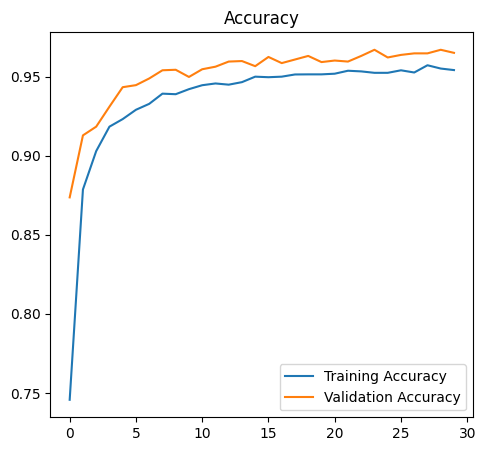

In [19]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

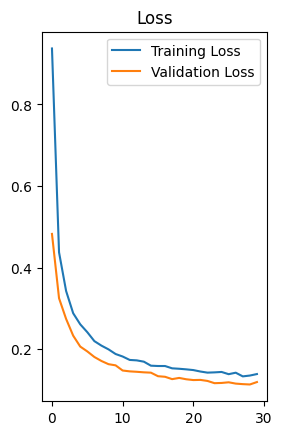

In [20]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()


In [21]:
model.save("plant_disease_efficientnetb0.keras")
print("Model saved to plant_disease_efficientnetb0.keras")

import json
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print("Class names saved to class_names.json")


Model saved to plant_disease_efficientnetb0.keras
Class names saved to class_names.json


In [25]:
import shutil
import os

files = [
    "/kaggle/working/plant_disease_efficientnetb0.keras",
    "/kaggle/working/class_names.json"
]

shutil.make_archive(
    "/kaggle/working/plant_disease_model",
    "zip",
    "/kaggle/working",
    base_dir="."
)

print(os.path.getsize("/kaggle/working/plant_disease_model.zip"))

15261734


In [22]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents', 'class_names.json', 'plant_disease_efficientnetb0.keras']


In [27]:
import os
print(os.path.exists("/kaggle/working/plant_disease_efficientnetb0.keras"))
print(os.path.exists("/kaggle/working/class_names.json"))

True
True
